In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Kousalya Kethireddy

## Data Analytics

### Level 1 - Task 3: Cleaning Data

In [2]:
df = pd.read_csv("train.csv")
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [3]:
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nData Types:")
print(df.dtypes)

Dataset Shape: (891, 12)

Column Names:
['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked']

Data Types:
PassengerId      int64
Survived         int64
Pclass           int64
Name               str
Sex                str
Age            float64
SibSp            int64
Parch            int64
Ticket             str
Fare           float64
Cabin              str
Embarked           str
dtype: object


In [4]:
df.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [5]:
missing_values = df.isnull().sum()

print("Missing Values:")
print(missing_values)

Missing Values:
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64


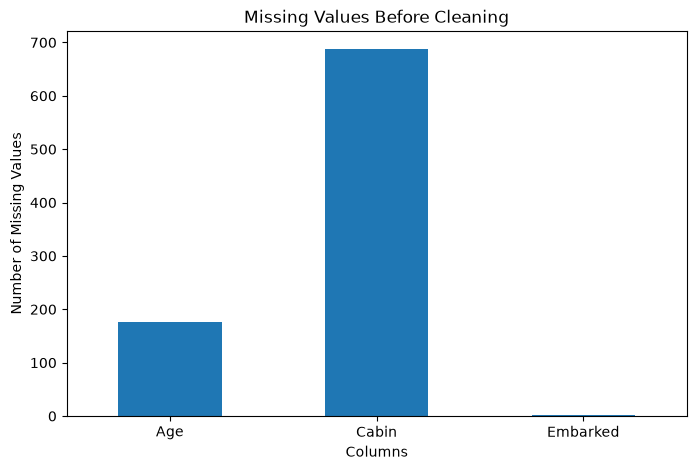

In [6]:
missing_plot = df.isnull().sum()
missing_plot = missing_plot[missing_plot > 0]

plt.figure(figsize=(8,5))
missing_plot.plot(kind="bar")
plt.title("Missing Values Before Cleaning")
plt.xlabel("Columns")
plt.ylabel("Number of Missing Values")
plt.xticks(rotation=0)
plt.show()

In [7]:
df["Age"] = df["Age"].fillna(df["Age"].median())
df["Cabin"] = df["Cabin"].fillna("Unknown")
df["Embarked"] = df["Embarked"].fillna(df["Embarked"].mode()[0])

print("Missing values handled successfully.")
print(df.isnull().sum())

Missing values handled successfully.
PassengerId    0
Survived       0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Cabin          0
Embarked       0
dtype: int64


In [8]:
duplicates_before = df.duplicated().sum()

print("Duplicate rows:", duplicates_before)

df = df.drop_duplicates()

print("Rows after removing duplicates:", len(df))

Duplicate rows: 0
Rows after removing duplicates: 891


In [9]:
print("Sex values:")
print(df["Sex"].value_counts())

print("\nEmbarked values:")
print(df["Embarked"].value_counts())

Sex values:
Sex
male      577
female    314
Name: count, dtype: int64

Embarked values:
Embarked
S    646
C    168
Q     77
Name: count, dtype: int64


In [10]:
df["Age"] = pd.to_numeric(df["Age"], errors="coerce")
df["Fare"] = pd.to_numeric(df["Fare"], errors="coerce")

print(df.dtypes)

PassengerId      int64
Survived         int64
Pclass           int64
Name               str
Sex                str
Age            float64
SibSp            int64
Parch            int64
Ticket             str
Fare           float64
Cabin              str
Embarked           str
dtype: object


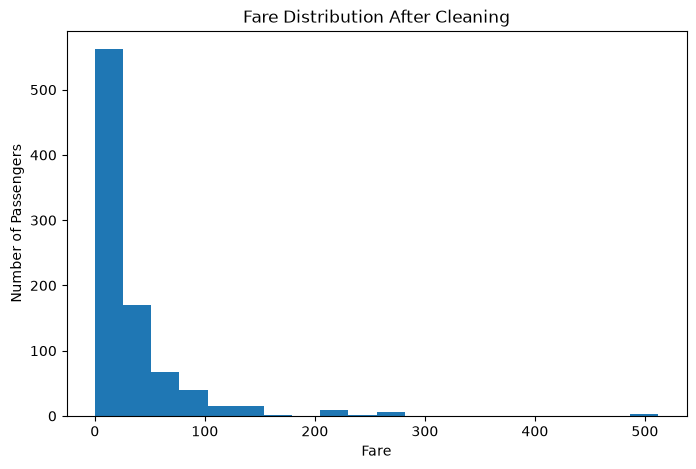

In [11]:
plt.figure(figsize=(8,5))
plt.hist(df["Fare"], bins=20)
plt.title("Fare Distribution After Cleaning")
plt.xlabel("Fare")
plt.ylabel("Number of Passengers")
plt.show()

In [12]:
Q1 = df["Fare"].quantile(0.25)
Q3 = df["Fare"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = df[
    (df["Fare"] < lower_bound) |
    (df["Fare"] > upper_bound)
]

print("Number of Fare outliers:", len(outliers))
print("Lower bound:", lower_bound)
print("Upper bound:", upper_bound)

Number of Fare outliers: 116
Lower bound: -26.724
Upper bound: 65.6344


## Outlier Handling

Fare outliers were detected using the IQR method.

These values were retained because they can represent legitimate differences in passenger fares, especially for passengers travelling in higher classes.

Therefore, the outliers were not removed.

In [13]:
print("BEFORE CLEANING")
print("Rows:", 891)
print("Missing values:", 866)
print("Duplicate rows:", 0)

print("\nAFTER CLEANING")
print("Rows:", len(df))
print("Missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

BEFORE CLEANING
Rows: 891
Missing values: 866
Duplicate rows: 0

AFTER CLEANING
Rows: 891
Missing values: 0
Duplicate rows: 0


In [14]:
print("Final dataset shape:", df.shape)

print("\nRemaining missing values:")
print(df.isnull().sum())

print("\nRemaining duplicate rows:", df.duplicated().sum())

Final dataset shape: (891, 12)

Remaining missing values:
PassengerId    0
Survived       0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Cabin          0
Embarked       0
dtype: int64

Remaining duplicate rows: 0


In [15]:
df.to_csv("cleaned_titanic.csv", index=False)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


## Conclusion

The Titanic dataset was successfully cleaned and prepared for analysis.

The cleaning process included:
- Inspecting the dataset structure and data types
- Identifying missing values
- Handling missing Age, Cabin, and Embarked values
- Checking and removing duplicate records
- Verifying numerical data types
- Detecting Fare outliers using the IQR method
- Retaining legitimate outliers
- Verifying the cleaned dataset
- Saving the final dataset as cleaned_titanic.csv

Two visualizations were also created to understand the missing values and Fare distribution.

The final dataset is clean and ready for further analysis.